In [1]:
from tensorflow.keras.layers import SimpleRNN,LSTM,GRU,Bidirectional,Dense,Embedding

In [2]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
import numpy as np

In [3]:
vocab_size = 500
(x_train,y_train),(x_test,y_test) = imdb.load_data(num_words=vocab_size)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
word_idx = imdb.get_word_index()
word_idx = {i:word_idx[word] for word,i in word_idx.items()}

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
print("Max length of a review::", len(max((x_train+x_test),
key=len)))

Max length of a review:: 2697


In [6]:
print("Min length of a review::", len(min((x_train+x_test),
key=len)))


Min length of a review:: 70


In [7]:
from tensorflow.keras.preprocessing import sequence
max_words = 400
x_train = sequence.pad_sequences(x_train,maxlen=max_words)
x_test = sequence.pad_sequences(x_test,maxlen=max_words)

In [14]:
x_valid,y_valid = x_train[:64],y_train[:64]
x_train_,y_train_ = x_train[64:],y_train[64:]

In [12]:
embd_len = 32
RNN_model = Sequential(name="Simple_RNN")
RNN_model.add(Embedding(vocab_size,embd_len,input_length=max_words))
RNN_model.add(SimpleRNN(128,activation='tanh',return_sequences=False))
RNN_model.add(Dense(1,activation='sigmoid'))
RNN_model.compile(
    loss = "binary_crossentropy",
    optimizer = "adam",
    metrics = ["accuracy"]
)

In [15]:
history = RNN_model.fit(
    x_train_,y_train_,
    batch_size = 64,
    epochs = 5,
    verbose=1,
    validation_data = (x_valid,y_valid)
)

Epoch 1/5
389/389 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.5156 - loss: 0.6942 - val_accuracy: 0.5469 - val_loss: 0.6772
Epoch 2/5
389/389 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.5425 - loss: 0.6833 - val_accuracy: 0.5938 - val_loss: 0.6477
Epoch 3/5
389/389 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.6544 - loss: 0.6250 - val_accuracy: 0.6562 - val_loss: 0.6388
Epoch 4/5
389/389 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.6606 - loss: 0.6212 - val_accuracy: 0.6094 - val_loss: 0.6150
Epoch 5/5
389/389 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.6723 - loss: 0.6023 - val_accuracy: 0.5781 - val_loss: 0.6588


In [16]:
print("Simple_RNN Score---> ",
RNN_model.evaluate(x_test, y_test,
verbose=0))

Simple_RNN Score--->  [0.6486092209815979, 0.6044800281524658]


In [18]:
y_train

array([1, 1, 1, ..., 0, 1, 0])

In [34]:
y_pred = RNN_model.predict(x_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step


In [35]:
y_pred

array([[0.48645684],
       [0.4866561 ],
       [0.3685617 ],
       ...,
       [0.57271504],
       [0.17089485],
       [0.4291108 ]], dtype=float32)

In [36]:
for i in range(0,len(y_pred)):
  if y_pred[i]>=0.5:
    y_pred[i] = 1
  else:
    y_pred[i] = 0

In [37]:
y_pred

array([[0.],
       [0.],
       [0.],
       ...,
       [1.],
       [0.],
       [0.]], dtype=float32)

In [38]:
y_test

array([0, 1, 1, ..., 0, 0, 0])

In [39]:
from sklearn.metrics import confusion_matrix

In [40]:
cm = confusion_matrix(y_test,y_pred)

Text(158.22222222222223, 0.5, 'Actual review')

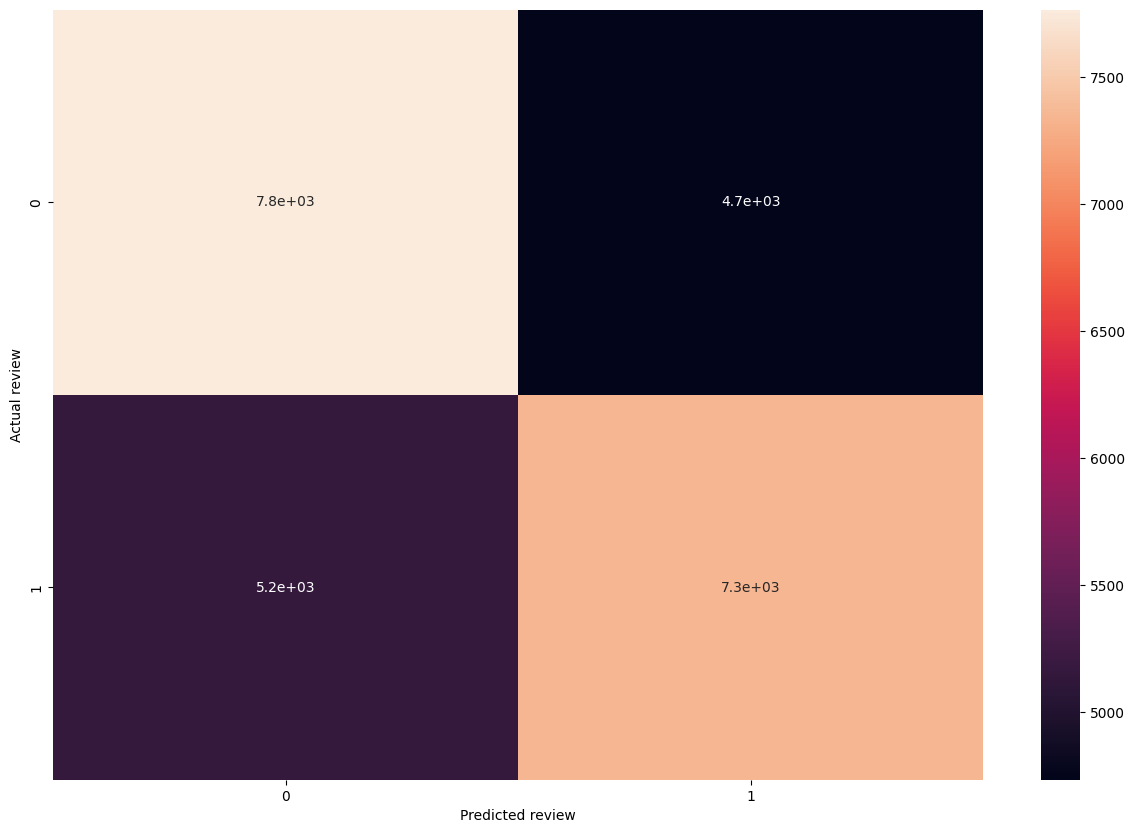

In [41]:
import seaborn as sn
import matplotlib.pyplot as plt
plt.figure(figsize = (15,10))
sn.heatmap(cm,annot=True)
plt.xlabel('Predicted review')
plt.ylabel('Actual review')